In [31]:
import happi
import math
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import scipy.constants as scon
from scipy.optimize import curve_fit
import matplotlib.ticker as ticker
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.colors import LogNorm
from matplotlib.colors import SymLogNorm
# from scipy.interpolate import griddata
# from scipy.signal import convolve2d
# from scipy.ndimage import gaussian_filter, laplace
from itertools import cycle
import time
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import FuncFormatter
import matplotlib.patches as patches
import matplotlib.ticker as tkr
from scipy.integrate import simpson
# from scipy.integrate import quad
import matplotlib.cm as cm
import matplotlib.colors
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import uniform_filter1d

# import seaborn as sns


In [32]:
# Set font properties
# %matplotlib inline
plt.rcParams['figure.figsize'] = [16,9]
# plt.rcParams["font.family"] = "TimesNewRoman"
# # # plt.rcParams["font.size"] = 25  # Adjust size if needed
plt.rcParams["axes.labelweight"] = "bold"  # Make labels thicker
plt.rcParams["font.weight"] = "bold"       # Set global font weight
# plt.rcParams["figure.dpi"] = 200  # Increase DPI for better rendering
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['mathtext.default'] = 'bf'

In [33]:
from importlib import reload
import ticks_grids_clean
reload(ticks_grids_clean)
from ticks_grids_clean import plot_trajectory_line_collection, set_ticks_and_grids, get_style_marker
from ticks_grids_clean import plot_discrete_colored_styled_curve, set_spine_linewidth, add_colorbar
from ticks_grids_clean import compute_Ay 
from ticks_grids_clean import general_compute_Ay, to_NyNx, compute_Az_from_BxBy, plot_row4_jz_with_Ay
import fitting_beta
reload(fitting_beta)
from fitting_beta import particle_2d_fields, particle_1d_yavg_safe, compute_total_pressure_2d, fit_sech2_to_beta, fit_beta_profile_width, fit_By_tanh
from fitting_beta import tanh_model, fit_By_tanh_normalized
# from ticks_grids_clean import _orient_to_NzNx
print(dir(ticks_grids_clean), dir(fitting_beta))

['Bbox', 'BoundaryNorm', 'Line2D', 'LineCollection', 'ListedColormap', 'MarkerStyle', 'ScalarMappable', 'SymLogNorm', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_orient_to_NzNx', 'add_colorbar', 'compute_Ay', 'compute_Az_from_BxBy', 'cumulative_gauss_quad', 'fit_By_tanh_normalized', 'general_compute_Ay', 'get_style_marker', 'leggauss', 'make_axes_locatable', 'np', 'plot_discrete_colored_styled_curve', 'plot_row4_jz_with_Ay', 'plot_trajectory_line_collection', 'plt', 'set_spine_linewidth', 'set_ticks_and_grids', 'smooth_field_y', 'tanh_model', 'ticker', 'tkr', 'to_NyNx', 'to_rgba', 'uniform_filter1d'] ['PARTICLE_MAP', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_fetch_particle_diag', '_try_get_axes', 'compute_total_pressure_2d', 'curve_fit', 'fit_By_tanh', 'fit_By_tanh_normalized', 'fit_beta_profile_width', 'fit_sech2_to_beta', 'gaussian_filter1d', 'np', 'partic

In [34]:
from importlib import reload
import ticks_grids_clean
reload(ticks_grids_clean)
from ticks_grids_clean import plot_trajectory_line_collection, set_ticks_and_grids, get_style_marker
from ticks_grids_clean import plot_discrete_colored_styled_curve, set_spine_linewidth, add_colorbar
from ticks_grids_clean import compute_Ay 
from ticks_grids_clean import general_compute_Ay, to_NyNx, compute_Az_from_BxBy, plot_row4_jz_with_Ay, smooth_field_y
import fitting_beta
reload(fitting_beta)
from fitting_beta import particle_2d_fields, particle_1d_yavg_safe, compute_total_pressure_2d, fit_sech2_to_beta, fit_beta_profile_width, fit_By_tanh
from fitting_beta import tanh_model, fit_By_tanh_normalized
# from ticks_grids_clean import _orient_to_NzNx
print(dir(ticks_grids_clean), dir(fitting_beta))

['Bbox', 'BoundaryNorm', 'Line2D', 'LineCollection', 'ListedColormap', 'MarkerStyle', 'ScalarMappable', 'SymLogNorm', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_orient_to_NzNx', 'add_colorbar', 'compute_Ay', 'compute_Az_from_BxBy', 'cumulative_gauss_quad', 'fit_By_tanh_normalized', 'general_compute_Ay', 'get_style_marker', 'leggauss', 'make_axes_locatable', 'np', 'plot_discrete_colored_styled_curve', 'plot_row4_jz_with_Ay', 'plot_trajectory_line_collection', 'plt', 'set_spine_linewidth', 'set_ticks_and_grids', 'smooth_field_y', 'tanh_model', 'ticker', 'tkr', 'to_NyNx', 'to_rgba', 'uniform_filter1d'] ['PARTICLE_MAP', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_fetch_particle_diag', '_try_get_axes', 'compute_total_pressure_2d', 'curve_fit', 'fit_By_tanh', 'fit_By_tanh_normalized', 'fit_beta_profile_width', 'fit_sech2_to_beta', 'gaussian_filter1d', 'np', 'partic

In [35]:
from importlib import reload
import x_o_points_detection
reload(x_o_points_detection)
# from x_o_points_detection import detect_xo_points, general_compute_Ay, filter_x_points_by_Ay, find_periodic_o_points
# from x_o_points_detection import find_boundary_o_point, deduplicate_points, find_periodic_o_points, compute_rms_electric_fields
# from x_o_points_detection import deduplicate_points_topo, filter_and_pair_xo_points

import x_o_points_detection_modified
reload(x_o_points_detection_modified)
from x_o_points_detection_modified import detect_xo_points, filter_x_points_by_Ay_mod, filter_o_points_by_Ay, filter_o_points_by_Ay_mod, filter_o_points_by_Ay_mod_more
from x_o_points_detection_modified import to_NyNx, compute_Az_from_BxBy, prune_close_o_and_adjacent_x, compute_rms_electric_fields, Ay_minmax_at_x_nearest
print(dir(x_o_points_detection))

['BoundaryNorm', 'Line2D', 'LineCollection', 'ListedColormap', 'MarkerStyle', 'ScalarMappable', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_orient_to_NzNx', 'center_of_mass', 'compute_rms_electric_fields', 'deduplicate_points', 'deduplicate_points_topo', 'detect_xo_points', 'filter_and_pair_xo_points', 'filter_x_points_by_Ay', 'find_boundary_o_point', 'find_periodic_o_points', 'gaussian_filter', 'general_compute_Ay', 'label', 'leggauss', 'make_axes_locatable', 'ndimage', 'np', 'plt', 'ticker']


In [36]:
from importlib import reload
import pressure_related
reload(pressure_related)
from pressure_related import particle_2d_fields, particle_1d_yavg, particle_1d_yavg_safe, compute_pressure_and_beta, find_trim_index_right
from pressure_related import trim_right_region_with_margin, compute_inverse_beta, user_model_inverse_beta, find_contiguous_regions_above_threshold
from pressure_related import fit_inverse_beta_transition, trim_right_vacuum_region, fit_inverse_beta_pipeline_cleaned
from pressure_related import inv_model, preprocess_inv, pick_fitting_region, robust_fit_inv, fit_inverse_beta_pipeline_improved
from pressure_related import model_Pmag, model_Pgas_fixedx0, model_Ptot, fit_pressures_all, compute_2d_thermal_pressures_from_particlebinning, current_sheet_pressure_stats
from pressure_related import get_equilibrium_times_from_energies
print(dir(pressure_related))

['FFMpegWriter', 'FuncAnimation', 'FuncFormatter', 'LogNorm', 'MultipleLocator', 'PARTICLE_MAP', 'SymLogNorm', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_compute_asymptotic_difference', '_fetch_particle_diag', '_fetch_pb_2d', '_find_three_point_anchors', '_infer_xy_order', '_initial_guess_for_tanh', '_make_current_sheet_mask', '_masked_stats', '_pb_get_axis', '_safe_divide', '_species_thermal_pressure_2d', '_try_get_axes', 'cm', 'compute_2d_thermal_pressures_from_particlebinning', 'compute_inverse_beta', 'compute_j_v_species_1d', 'compute_pressure_and_beta', 'current_sheet_pressure_stats', 'curve_fit', 'cycle', 'find_contiguous_regions_above_threshold', 'find_trim_index_right', 'fit_inverse_beta_pipeline_cleaned', 'fit_inverse_beta_pipeline_improved', 'fit_inverse_beta_transition', 'fit_pressures_all', 'gaussian_filter1d', 'get_equilibrium_times_from_energies', 'happi', 'inv_model', 'least_squares', 'math', 'matplotlib', 

In [37]:
################################################################################################################################
##################                                 For length normalized runs                                 ##################
################################################################################################################################

mass_ratio  = 100.0                            ##m_i/m_e
di          = np.sqrt(mass_ratio)           ## di = np.sqrt(mass_ratio)*de, de = 1.0 in Smilei
ion_mass    = mass_ratio
Delta       = 2.0                         ## width of the CS in terms of di
lamb_i      = Delta*di
Lx          = 6.4*lamb_i
dx          = 0.00625*lamb_i
dy          = dx
Nx          = int(Lx/dx)

aspect_ratio= 1.0/2.0                        ## by definition: Lx/Ly = aspect_ratio; for Ly>Lx: aspect_ratio < 1.0
Ly          = Lx/aspect_ratio
Ny          = int(Ly//dy)                                                                                               
dt_CFL      = (dx**-2+dy**-2)**-0.5                                                                                     
dt          = 0.95 * dt_CFL 

R       = 0.5                           ## Asymmetry in B-field
alpha   = 0.45                          ## asymmetry in density
eta_CA  = 10.0 # np.sqrt(mass_ratio)                          ## eta_CA = c/VA = omega_pi/Omega_i
tau     = 1.0                           ## temp_ratio i.e. Ti/Te NOT in theta
r       = 1/8
beta    = 4.0
n0      = 1.0                           ## number density
B0      = (1.0/eta_CA)*(np.sqrt(mass_ratio*n0))                 ## equilibrium magnetic field
theta_e = (R/alpha)*(1.0/(1.0+tau))*(mass_ratio/(eta_CA**2))    ## initial electron temperature in dimensionless unit
# theta_e = (1.0/4.0)*(mass_ratio/(eta_CA**2)) 
theta_i = (tau)*theta_e                                         ## initial ion temperature in m_e*c**2
# theta_e_neq = beta*theta_e
# theta_i_neq = beta*theta_i
theta_e_neq = r*theta_e
theta_i_neq = r*theta_i

f = 0.1
delta_beta = r*(((8.0*R**2/alpha)+4.0*R*((R-1)**2)+f**2)/((R**2-1)**2+2*f**2*(R**2+1.0)+f**4))

lambda_de = np.sqrt(theta_e_neq)
lambda_di = np.sqrt(theta_i_neq/mass_ratio)*di

VA0 = B0/(np.sqrt(ion_mass*n0))
t_cross = VA0/(250)

print(lambda_de/dx, lambda_di/dx)
print( dx, dy, di/dx, 1/dx)
print(dt, dt_CFL, Nx, Ny)
print(delta_beta, t_cross)

2.1081851067789197 2.1081851067789197
0.125 0.125 80.0 8.0
0.08396893026590252 0.08838834764831845 1024 2048
1.0539577187807276 0.0004


In [16]:
####################################################################################################################
#######                                           Without guide field                                        #######
####################################################################################################################
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point125")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point125/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point25")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point25/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point5")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_point5/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_1point25/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_3/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_di/r_5/")

# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point125")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point125/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point5")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point5/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/temp_vary")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_1point25")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_1point5")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/temp_vary/alpha_temp_point15/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_3")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_3/cs_position_left/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_5/cs_position_left/")
S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_3/cs_position_left/reflective_boundary/")


# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point125")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point125/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point25")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point25/reflective_boundary/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point5")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_4di/r_point5/reflective_boundary/")

# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/phase_space/")
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/phase_space/full_domain_y/")

### equilibrium or r = 1
# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_1")

# S = happi.Open("/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point25/ekin/2d/mass_ratio_400/")


Loaded simulation '/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_3/cs_position_left/reflective_boundary/'
Scanning for Scalar diagnostics
Scanning for Field diagnostics
Scanning for Probe diagnostics
Scanning for ParticleBinning diagnostics
Scanning for RadiationSpectrum diagnostics
Scanning for Performance diagnostics
Scanning for Screen diagnostics
Scanning for Tracked particle diagnostics
Scanning for new particle diagnostics


In [38]:
Bx1      = S.Field(0,'Bx')
By1      = S.Field(0,'By')

time_step  = By1.getTimesteps()
time_snap = By1.getTimes()
print(time_step.shape)
# Bx1.slide(cmap='PRGn_r',figure=1,vmin=-0.1,vmax=0.1)
# Bx1.plot(timestep=time_step[1], cmap='PRGn_r', vmin=-0.4, vmax=0.4)
# By1.plot(timestep=time_step[5], cmap='PuOr', norm = SymLogNorm(linthresh=1.0e-2, linscale=1.0, vmin = -1.8, vmax = 1.8))  #vmin=-1.8, vmax=1.8)

(201,)


In [39]:
import numpy as np

def compute_rms_electric_fields_mod(
    Ex_data, Ey_data, Ez_data,
    x_points, y_points,
    x_range, y_range,
    *,
    no_x_fallback="max",      # "max" or "domain_rms" or "zero"
    region_mask=None,         # optional boolean mask with same shape as Ex_data
    sheet_slice=None,         # optional slice over x-index for current-sheet window
    x_line=None               # optional physical x-coordinate for line max |Ez|
):
    """
    Compute RMS of Ez and |E| at X-points, plus:
      - maximum |Ez| in a current-sheet window (sheet_slice),
      - maximum |Ez| along a vertical line x = x_line.

    Parameters
    ----------
    Ex_data, Ey_data, Ez_data : 2D arrays (shape: [nx, ny])
        Electric field components.
    x_points, y_points : 1D arrays
        Coordinates of X-points (filtered & final).
    x_range, y_range : 1D arrays
        Grid coordinates (used to map coords -> indices).
    no_x_fallback : str
        - "max"        : Ez_rms = max(|Ez|), Emag_rms = max(|E|)
        - "domain_rms" : Ez_rms = RMS over whole domain, Emag_rms = RMS over whole domain
        - "zero"       : Ez_rms = Emag_rms = 0.0
    region_mask : 2D bool array or None
        If provided, fallback metrics are computed only where region_mask is True.
    sheet_slice : slice or None
        Slice over the x-index specifying the current-sheet window,
        typically something like slice(ix_left, ix_right) corresponding to
        x in [x0 - w, x0 + w]. If None, the window is the full domain.
    x_line : float or None
        Physical x-coordinate of the vertical line on which we want the
        maximum of |Ez|. If None, no line maximum is computed and NaNs
        are returned for those outputs.

    Returns
    -------
    Ez_rms : float
        RMS of Ez at X-points (or fallback value if no X-points).
    Emag_rms : float
        RMS of |E| at X-points (or fallback value if no X-points).
    Ez_values : 1D array
        Ez at each X-point (or empty if no X-points and fallback="zero").
    Emag_values : 1D array
        |E| at each X-point (or empty if no X-points and fallback="zero").
    Ez_max_abs_window : float
        Maximum of |Ez| in the current-sheet window (or full domain if sheet_slice=None).
    x_Ez_max_window : float
        x-coordinate of location where |Ez| attains Ez_max_abs_window.
    y_Ez_max_window : float
        y-coordinate of location where |Ez| attains Ez_max_abs_window.
    Ez_max_abs_line : float
        Maximum of |Ez| along the vertical line x = x_line (NaN if x_line is None).
    x_Ez_max_line : float
        x-coordinate of that line maximum (x_line snapped to nearest grid; NaN if x_line is None).
    y_Ez_max_line : float
        y-coordinate of that line maximum (NaN if x_line is None).
    """

    # Ensure arrays
    x_points = np.asarray(x_points)
    y_points = np.asarray(y_points)

    nx, ny = Ez_data.shape

    # ----------------- Max |Ez| in current-sheet window -----------------
    if sheet_slice is None:
        # full x-range
        x_idx_window = np.arange(nx)
        Ez_window = Ez_data  # shape (nx, ny)
    else:
        x_idx_window = np.arange(nx)[sheet_slice]
        Ez_window = Ez_data[sheet_slice, :]  # shape (n_window_x, ny)

    abs_Ez_window = np.abs(Ez_window)
    flat_idx_win = np.argmax(abs_Ez_window)
    ix_rel_win, iy_rel_win = np.unravel_index(flat_idx_win, abs_Ez_window.shape)

    ix_max_win = x_idx_window[ix_rel_win]  # index in full domain
    iy_max_win = iy_rel_win               # full y index

    Ez_max_abs_window = float(abs_Ez_window[ix_rel_win, iy_rel_win])
    x_Ez_max_window = float(x_range[ix_max_win])
    y_Ez_max_window = float(y_range[iy_max_win])

    # ----------------- Max |Ez| along x = x_line (if requested) -----------------
    if x_line is not None:
        # nearest x index to the requested x_line
        ix_line = int(np.argmin(np.abs(x_range - x_line)))
        abs_Ez_line = np.abs(Ez_data[ix_line, :])  # shape (ny,)
        iy_max_line = int(np.argmax(abs_Ez_line))

        Ez_max_abs_line = float(abs_Ez_line[iy_max_line])
        x_Ez_max_line = float(x_range[ix_line])
        y_Ez_max_line = float(y_range[iy_max_line])
    else:
        Ez_max_abs_line = float("nan")
        x_Ez_max_line = float("nan")
        y_Ez_max_line = float("nan")

    # Helper: coord -> nearest index
    def nearest_indices(x, y):
        ix = np.argmin(np.abs(x_range - x))
        iy = np.argmin(np.abs(y_range - y))
        return ix, iy

    # ----------------- No X-points: fallback RMS -----------------
    if x_points.size == 0:
        if no_x_fallback == "zero":
            return (
                0.0,          # Ez_rms
                0.0,          # Emag_rms
                np.array([]), # Ez_values
                np.array([]), # Emag_values
                Ez_max_abs_window,
                x_Ez_max_window,
                y_Ez_max_window,
                Ez_max_abs_line,
                x_Ez_max_line,
                y_Ez_max_line,
            )

        # Compute over full domain or masked region
        if region_mask is None:
            Ex_sel, Ey_sel, Ez_sel = Ex_data, Ey_data, Ez_data
        else:
            m = np.asarray(region_mask, dtype=bool)
            if m.shape != Ex_data.shape:
                raise ValueError(
                    f"region_mask shape {m.shape} must match field shape {Ex_data.shape}"
                )
            Ex_sel = Ex_data[m]
            Ey_sel = Ey_data[m]
            Ez_sel = Ez_data[m]

        Emag_sel = np.sqrt(Ex_sel**2 + Ey_sel**2 + Ez_sel**2)

        if no_x_fallback == "max":
            Ez_rms = float(np.max(np.abs(Ez_sel)))
            Emag_rms = float(np.max(Emag_sel))
            return (
                Ez_rms,
                Emag_rms,
                np.array([Ez_rms]),
                np.array([Emag_rms]),
                Ez_max_abs_window,
                x_Ez_max_window,
                y_Ez_max_window,
                Ez_max_abs_line,
                x_Ez_max_line,
                y_Ez_max_line,
            )

        if no_x_fallback == "domain_rms":
            Ez_rms = float(np.sqrt(np.mean(Ez_sel**2)))
            Emag_rms = float(np.sqrt(np.mean(Emag_sel**2)))
            return (
                Ez_rms,
                Emag_rms,
                np.array([Ez_rms]),
                np.array([Emag_rms]),
                Ez_max_abs_window,
                x_Ez_max_window,
                y_Ez_max_window,
                Ez_max_abs_line,
                x_Ez_max_line,
                y_Ez_max_line,
            )

        raise ValueError(f"Unknown no_x_fallback='{no_x_fallback}'")

    # ----------------- X-points exist: compute RMS at X-points -----------------
    Ez_values = []
    Emag_values = []

    for x, y in zip(x_points, y_points):
        ix, iy = nearest_indices(x, y)
        Ex_val = Ex_data[ix, iy]
        Ey_val = Ey_data[ix, iy]
        Ez_val = Ez_data[ix, iy]

        Ez_values.append(Ez_val)
        Emag_values.append(np.sqrt(Ex_val**2 + Ey_val**2 + Ez_val**2))

    Ez_values = np.asarray(Ez_values)
    Emag_values = np.asarray(Emag_values)

    Ez_rms = float(np.sqrt(np.mean(Ez_values**2)))
    Emag_rms = float(np.sqrt(np.mean(Emag_values**2)))

    return (
        Ez_rms,
        Emag_rms,
        Ez_values,
        Emag_values,
        Ez_max_abs_window,
        x_Ez_max_window,
        y_Ez_max_window,
        Ez_max_abs_line,
        x_Ez_max_line,
        y_Ez_max_line,
    )


In [40]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tkr
from matplotlib.colors import SymLogNorm, LinearSegmentedColormap
from matplotlib.transforms import Bbox


def _smooth_y_window(Jz_xy, y_axis, window_phys):
    Jz_xy = np.asarray(Jz_xy, float)
    y_axis = np.asarray(y_axis, float)

    if window_phys is None or window_phys <= 0 or y_axis.size < 2:
        return Jz_xy

    dy = float(np.nanmedian(np.diff(y_axis)))
    if not np.isfinite(dy) or dy <= 0:
        return Jz_xy

    halfwin = int(np.round(0.5 * window_phys / dy))
    if halfwin < 1:
        return Jz_xy

    k = 2 * halfwin + 1
    kernel = np.ones(k, float) / k

    pad = halfwin
    A = np.pad(Jz_xy, ((0, 0), (pad, pad)), mode="edge")
    out = np.empty_like(Jz_xy)
    for ix in range(A.shape[0]):
        out[ix, :] = np.convolve(A[ix, :], kernel, mode="valid")
    return out


def plot_grid_jz_with_Ay_journal(
    S,
    frames,
    nrows,
    ncols,
    *,
    di,
    B0,
    lamb_i,
    # ---------------- data / normalization ----------------
    min_val=-2.2,
    max_val=2.2,
    linthresh=1e-3,
    linscale=1.0,
    aspect="auto",
    # ---------------- contours ----------------
    show_Ay_contours=True,
    n_contours=25,
    contour_percentiles=(5, 95),
    # ---------------- smoothing ----------------
    yavg_window_di=None,
    # ---------------- figure geometry ----------------
    figsize=(6, 8),
    left=0.12,
    right=0.86,
    bottom=0.11,
    top=0.96,
    wspace=0.06,
    hspace=0.04,
    # ---------------- shared labels ----------------
    shared_xlabel=r"$\mathbf{x/\lambda_i}$",
    shared_ylabel=r"$y/\lambda_i$",
    supxlabel_y=0.04,
    supylabel_x=0.04,
    # ---------------- colorbar ----------------
    cbar_pad=0.015,
    cbar_width=0.020,
    cbar_length=0.92,
    cbar_top_text=r"$\mathbf{J_z}$",
    # ---------------- panel labels ----------------
    # panel_label_style=("A", "B", "C", "D", "E", "F", "G", "H", "I",
    #                    "J", "K", "L", "M", "N", "O", "P", "Q", "R"),
    panel_label_style=("(a)", "(b)", "(c)", "(d)", "(e)", "(f)",
                       "(g)", "(h)", "(i)", "(j)", "(k)", "(l)",
                       "(m)", "(n)", "(o)", "(p)", "(q)", "(r)"),
    ls=15,
    # ---------------- optional extras ----------------
    show_sheet_width=False,
    window_size=1000,
    edge_fraction=0.1,
    smooth_sigma=0.0,
    min_variation=1.0,
):
    """
    Journal-style multi-panel Jz plot with:
      - shared x/y labels outside the subplot block
      - one manually placed shared colorbar on the right
      - optional Ay contours
      - optional X/O-point overlays if your helper functions exist
    """

    frames = list(frames)
    n_expected = nrows * ncols
    if len(frames) != n_expected:
        raise ValueError(
            f"Need exactly {n_expected} frames for a {nrows}x{ncols} grid, got {len(frames)}."
        )

    # ---------------- field handles ----------------
    Jz1 = S.Field(0, "Jz")
    Bx1 = S.Field(0, "Bx")
    By1 = S.Field(0, "By")

    time_step = Jz1.getTimesteps()
    time_snap = Jz1.getTimes()

    x_range = np.asarray(Jz1.getAxis("x"), dtype=float)
    y_range = np.asarray(Jz1.getAxis("y"), dtype=float)

    x_min, x_max = float(np.nanmin(x_range)), float(np.nanmax(x_range))
    y_min, y_max = float(np.nanmin(y_range)), float(np.nanmax(y_range))

    extent = np.array([x_min, x_max, y_min, y_max], dtype=float) / float(lamb_i)

    # ---------------- colormap / norm ----------------
    norm = SymLogNorm(
        linthresh=linthresh,
        linscale=linscale,
        vmin=min_val,
        vmax=max_val
    )

    cmap_bg_rich = LinearSegmentedColormap.from_list(
        "blue_white_gold_rich",
        ["#1E2A55", "#3B6AC4", "white", "#C4953B", "#5A3A10"],
        N=256
    )

    x_point_color = "#D95D26"  #"#41FEE7"      
    o_point_color = "#DB24D3"  #"#71F609"        

    # ---------------- figure / axes ----------------
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=left,
        right=right,
        bottom=bottom,
        top=top,
        wspace=wspace,
        hspace=hspace
    )

    # normalize axes container to 2D
    axes = np.asarray(axes)
    if axes.ndim == 0:
        axes = axes[None, None]
    elif axes.ndim == 1:
        if nrows == 1:
            axes = axes[None, :]
        else:
            axes = axes[:, None]

    axes_flat = axes.ravel()
    im_for_cbar = None

    # ---------------- loop over panels ----------------
    for idx, frame in enumerate(frames):
        ax = axes_flat[idx]
        ts = time_step[frame]

        Jz_data = np.squeeze(np.array(Jz1.getData(timestep=ts)), axis=0)
        Bx_data = np.squeeze(np.array(Bx1.getData(timestep=ts)), axis=0)
        By_data = np.squeeze(np.array(By1.getData(timestep=ts)), axis=0)

        # optional y-smoothing
        if yavg_window_di is not None:
            Jz_plot = _smooth_y_window(Jz_data, y_range, float(yavg_window_di) * float(di))
        else:
            Jz_plot = Jz_data

        # -------- Ay computation if available --------
        Ay_smooth = None
        x_range_use, y_range_use = x_range, y_range

        if show_Ay_contours:
            if "detect_xo_points" in globals():
                try:
                    xX, yX, xO, yO, Ay_smooth, x_range2, y_range2 = detect_xo_points(
                        S, time_step, frame, sigma=2, grad_tol_factor=0.02
                    )

                    xX_filtered, yX_filtered, Ay_X_filtered, xO_global, yO_global, Ay_global_min = filter_x_points_by_Ay_mod(
                        Ay_smooth, x_range2, y_range2, xX, yX, xO, yO,
                        tol_Ay=0.2,
                        missing_O="return_empty"
                    )

                    if len(xX_filtered) == 0:
                        xO_filtered = np.array([])
                        yO_filtered = np.array([])
                        xX_sorted = np.array([])
                        yX_sorted = np.array([])
                    else:
                        xO_filtered, yO_filtered, xX_sorted, yX_sorted, alternation_ok, non_alternating_indices = (
                            filter_o_points_by_Ay_mod_more(
                                xO, yO,
                                xX_filtered, yX_filtered,
                                Ay_smooth, x_range2, y_range2,
                                y_min=np.min(y_range), y_max=np.max(y_range),
                                periodic=True, tol=1e-6
                            )
                        )

                    xO_filtered2, yO_filtered2, xX_sorted2, yX_sorted2, report = prune_close_o_and_adjacent_x(
                        xO_filtered, yO_filtered,
                        xX_sorted, yX_sorted,
                        Ay_smooth, x_range2, y_range2,
                        dist_tol=0.2 * di,
                        periodic_y=True,
                        y_min=np.min(y_range),
                        y_max=np.max(y_range),
                        verbose=False,
                    )

                    if len(xX_filtered) != 0:
                        ax.scatter(
                            xX_sorted2 / lamb_i,
                            yX_sorted2 / lamb_i,
                            color=x_point_color,
                            marker='x',
                            s=60,
                            linewidths=2.5,
                            zorder=5
                        )
                        ax.scatter(
                            xO_filtered2 / lamb_i,
                            yO_filtered2 / lamb_i,
                            color=o_point_color,
                            facecolors='none',
                            marker='o',
                            s=60,
                            linewidths=2.5,
                            zorder=5
                        )

                    if x_range2 is not None and y_range2 is not None:
                        x_range_use = np.asarray(x_range2, float)
                        y_range_use = np.asarray(y_range2, float)

                except Exception:
                    Ay_smooth = None
                    x_range_use, y_range_use = x_range, y_range

            elif "general_compute_Ay" in globals():
                try:
                    Ay_smooth = general_compute_Ay(x_range_use, y_range_use, Bx_data, By_data)
                except Exception:
                    Ay_smooth = None

        # -------- imshow --------
        im = ax.imshow(
            Jz_plot.T,
            origin="lower",
            extent=extent,
            cmap= 'PiYG',  #cmap_bg_rich,  PuOr   seismic    PRGn   Reds  vanimo   managua
            vmin = min_val, vmax = max_val,      #norm=norm,
            aspect=aspect,
            interpolation="nearest",
            rasterized=True
        )

        if im_for_cbar is None:
            im_for_cbar = im

        # -------- contours --------
        if show_Ay_contours and (Ay_smooth is not None):
            lo, hi = np.percentile(Ay_smooth, contour_percentiles)
            if np.isfinite(lo) and np.isfinite(hi) and hi > lo:
                levels = np.linspace(lo, hi, int(n_contours))
                ax.contour(
                    x_range_use / lamb_i,
                    y_range_use / lamb_i,
                    Ay_smooth,
                    levels=levels,
                    colors="k",
                    linewidths=0.6,  ##1.0
                    linestyles="solid"
                )

        # -------- limits --------
        ax.set_xlim(x_min / lamb_i, x_max / lamb_i)
        ax.set_ylim(y_min / lamb_i, y_max / lamb_i)

        # -------- ticks: only outer labels --------
        r = idx // ncols
        c = idx % ncols

        if c != 0:
            ax.tick_params(axis="y", labelleft=False)
        if r != nrows - 1:
            ax.tick_params(axis="x", labelbottom=False)

        # -------- panel label --------
        if idx < len(panel_label_style):
            ax.text(
                0.03, 0.92,
                panel_label_style[idx],
                transform=ax.transAxes,
                ha="left", va="top",
                fontsize=ls + 3,
                fontweight="bold",
                color="white",
                bbox=dict(facecolor="black", alpha=0.7, pad=2.5)
            )

        # -------- optional sheet-width text --------
        if show_sheet_width and ("fit_By_tanh_normalized" in globals()):
            try:
                _, _, _, _, _, w_fit, _, _, _ = fit_By_tanh_normalized(
                    S, frame, time_step, B0, di,
                    min_variation=min_variation,
                    window_size=window_size,
                    edge_fraction=edge_fraction,
                    smooth_sigma=smooth_sigma
                )
                w_di = float(w_fit / di)
                t_norm = time_snap[frame] / lamb_i
                ax.text(
                    0.7, 0.98,
                    rf"$ct/\lambda_0={t_norm:0.0f}$" + "\n" + rf"$\lambda/d_i={w_di:0.1f}$",
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=ls+3,
                    color="white",
                    bbox=dict(facecolor="black", alpha=0.75, pad=2.5),
                    zorder=10 
                )
            except Exception:
                pass

        # -------- optional style helpers --------
        try:
            set_spine_linewidth(ax, width=1.5, spines=['top', 'bottom', 'right', 'left'])
        except Exception:
            pass

        try:
            set_ticks_and_grids(
                ax,
                major_interval_x=2,
                major_interval_y=4,
                tick_labelsize=ls+5,
                major_tick_length=5,
                minor_tick_length=0,
                major_tick_width=3.0, ##1.8
                major_grid=False,
                minor_grid=False
            )
        except Exception:
            ax.tick_params(axis='both', labelsize=ls, width=1.4, length=5)

    # ---------------- shared labels ----------------
    fig.supxlabel(shared_xlabel, fontsize=ls+5, fontweight="bold", y=supxlabel_y)
    fig.supylabel(shared_ylabel, fontsize=ls+5, fontweight="bold", x=supylabel_x)

    # ---------------- shared colorbar ----------------
    bb = Bbox.union([ax.get_position() for ax in axes_flat])

    cbar_h = bb.height * float(cbar_length)
    cbar_y0 = bb.y0 + 0.5 * (bb.height - cbar_h)
    cbar_x0 = bb.x1 + float(cbar_pad)

    cax = fig.add_axes([cbar_x0, cbar_y0, float(cbar_width), cbar_h])

    cbar_ticks = np.linspace(min_val, max_val, 5)
    cbar = fig.colorbar(
        im_for_cbar,
        cax=cax,
        orientation="vertical",
        ticks=cbar_ticks,
        format=tkr.FormatStrFormatter("%.2f")
    )

    # cbar.ax.tick_params(labelsize=ls, width=1.5, length=5, direction="in", right=True)
    cbar.outline.set_linewidth(1.5)
    cbar.ax.tick_params(labelsize=ls+1, width=3.0, length=5.0)
    cbar.ax.tick_params(which="both", direction="in", right=True)
    try:
        set_spine_linewidth(cbar.ax, width=1.5, spines=['top', 'bottom', 'left', 'right'])
    except Exception:
        pass

    # cbar.ax.text(
    #     0.9, 1.02, 
    #     cbar_top_text,
    #     transform=cbar.ax.transAxes,
    #     ha="center", va="bottom",
    #     fontsize=30, fontweight="bold"
    # )

    cbar.ax.set_title(cbar_top_text, fontsize=ls+3, pad=4)
    #########

    return fig, axes, cbar

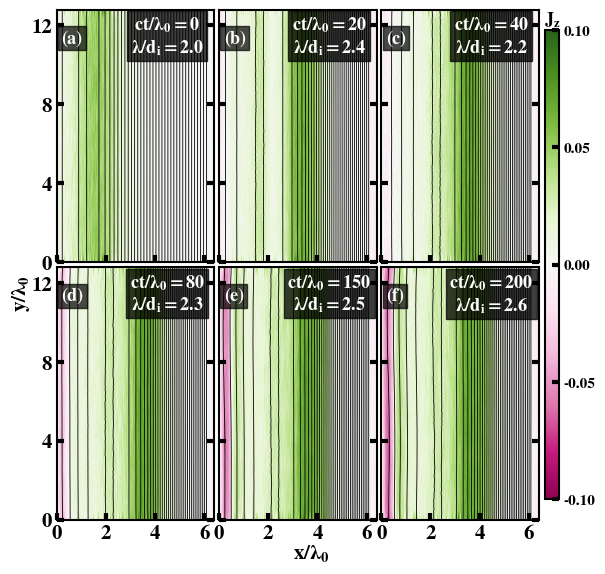

In [41]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIX Two Text", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
})

Jz1 = S.Field(0, "Jz")
nT = len(Jz1.getTimesteps())
MM = 1.0 / 25.4  # millimeters to inches


frames6 = [0, 20, 40, 80, 150, 200]  #75

fig, axes, cbar = plot_grid_jz_with_Ay_journal(
    S,
    frames=frames6,
    nrows=2,
    ncols=3,
    di=di,
    B0=B0,
    lamb_i=lamb_i,

    # data / display
    min_val=-0.10,
    max_val=0.10,
    n_contours=35,    ##15
    yavg_window_di=2.0,
    show_Ay_contours=True,
    show_sheet_width=True,

    # figure geometry
    # figsize=(8, 8),   # good journal size   7.2, 4.8
    figsize=(170 * MM, 160 * MM),
    left=0.12,
    right=0.84,
    bottom=0.14,
    top=0.95,
    wspace=0.03,
    hspace=0.02,

    # shared labels
    shared_xlabel=r"$\mathbf{x/\lambda_0}$",
    shared_ylabel=r"$y/\lambda_0$",
    supxlabel_y=0.07,  #0.05
    supylabel_x=0.05,  #0.035

    # colorbar
    cbar_pad=0.01,
    cbar_width=0.020,
    cbar_length=0.92,
    cbar_top_text=r"$\mathbf{J_z}$",

    # font scale
    ls=10,
)

# plt.savefig(f'jz_cs_width_2_r_1point25_all_6_temp_vary.pdf',
#             dpi=300, bbox_inches='tight')#, pad_inches=0, transparent=True)
# plt.savefig(f'jz_cs_width_2_r_point125_all_6.pdf',
#             dpi=300, bbox_inches='tight')#, pad_inches=0, transparent=True)
# plt.savefig(f'jz_cs_width_2_r_point125_all_6_reflective_bc.pdf',
#             dpi=600)#, bbox_inches='tight')#, pad_inches=0, transparent=True)
# plt.savefig(f'jz_cs_width_2_r_3_all_6_reflective_bc.pdf',
#             dpi=600)#, bbox_inches='tight')#, pad_inches=0, transparent=True)
plt.show()

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patheffects as pe
import happi


# ============================================================
# DATA SETS
# ============================================================
S_r0125 = happi.Open(
    "/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/"
    "length_normalized/cs_width_2di/r_point125/reflective_boundary/"
)

S_r3 = happi.Open(
    "/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/"
    "length_normalized/cs_width_2di/r_3/cs_position_left/"
    "reflective_boundary/"
)


# ============================================================
# REQUIRED OBJECTS
# ============================================================
# The following must already exist in your notebook/session:
#
#   ion_mass
#   time_step
#   di
#   B0
#   VA0
#
#   compute_pressure_and_beta(...)
#   fit_By_tanh_normalized(...)
#   set_ticks_and_grids(...)
# ============================================================


# ============================================================
# USER SETTINGS
# ============================================================
Delta = 2.0
lambda_i = Delta * di

step_interval = 1

frames_to_plot = list(
    range(
        0,
        len(time_step),
        step_interval
    )
)


# ============================================================
# TIME-UNIT SETTINGS
# ============================================================
# This controls the interpretation of `time_step`.
#
# Use:
#
#   "iteration"
#       if time_step contains Smilei iteration numbers.
#
#   "simulation_time"
#       if time_step already contains t in Smilei code units.
#
#   "ct_over_lambda_i"
#       if time_step already contains ct/lambda_i.
#
# happi getTimesteps() normally returns iteration numbers.
PRESSURE_TIME_UNITS = "iteration"


# This controls the interpretation of column 0 in the saved
# reconnection-rate data file.
#
# Use:
#
#   "iteration"
#       if column 0 contains Smilei iteration numbers.
#
#   "simulation_time"
#       if column 0 contains t in Smilei code units.
#
#   "ct_over_lambda_i"
#       if column 0 is already ct/lambda_i.
#
# Because your original expression was
#
#     gradient(Az_max_min_diff, time_E)
#
# "simulation_time" is the likely setting.
RECONNECTION_TIME_UNITS = "simulation_time"


# Normally leave this as None.
# Set a numerical value only if S.namelist.Main.timestep
# cannot be read.
SMILEI_DT_OVERRIDE = None


# ============================================================
# CURRENT-SHEET FIT SETTINGS
# ============================================================
window_size = 999
min_variation = 1.0
edge_fraction = 0.1
smooth_sigma = 0.0

# Set True only if fit_By_tanh_normalized returns x0 and w
# already expressed in d_i units.
x0w_are_in_di_units = False


# ============================================================
# CURRENT-SHEET REGION OVERLAY
# ============================================================
SHOW_CS_REGION = True
FILL_CS_REGION = True

CS_FILL_ALPHA = 0.16
CS_EDGE_COLOR = "white"
CS_EDGE_LW = 2.2
CS_EDGE_ALPHA = 0.95


# ============================================================
# RECONNECTION-RATE SETTINGS
# ============================================================
RATE_THRESHOLD = 0.025

cs_width = 2
r_value = 0.125
cs_position = 0.25
with_guidefield = 0

data_dir_E = Path(
    "asym_mag_rec/length_normalized/xo_points_E_file/"
)

# Draw the R=0.025 text label on the top-right panel
SHOW_RATE_LABEL = True

# Optional separate plot used to verify the threshold
PLOT_RECONNECTION_RATE_CHECK = False


# ============================================================
# PRESSURE COLORMAP
# ============================================================
CMAP_PRESSURE = "plasma"


# ============================================================
# HELPER: GET SMILEI TIMESTEP
# ============================================================
def get_smilei_timestep(S):
    """
    Return the Smilei timestep in simulation code units.
    """

    if SMILEI_DT_OVERRIDE is not None:
        return float(SMILEI_DT_OVERRIDE)

    try:
        return float(
            S.namelist.Main.timestep
        )

    except Exception as exc:
        raise RuntimeError(
            "Could not read S.namelist.Main.timestep. "
            "Set SMILEI_DT_OVERRIDE manually near the top "
            "of the script."
        ) from exc


# ============================================================
# HELPER: CONVERT TIME COORDINATES
# ============================================================
def convert_time_coordinate(
    values,
    units,
    S,
    lambda_i_value
):
    """
    Convert a time coordinate to both:

        t_code = simulation time in Smilei code units
        tau    = ct/lambda_i

    Smilei uses c=1 in normalized units, so:

        ct/lambda_i = t_code/lambda_i
    """

    values = np.asarray(
        values,
        dtype=float
    )

    if lambda_i_value <= 0.0:
        raise ValueError(
            "lambda_i_value must be positive."
        )

    if units == "iteration":

        dt_sim = get_smilei_timestep(S)

        t_code = values * dt_sim
        tau = t_code / lambda_i_value

    elif units == "simulation_time":

        t_code = values
        tau = t_code / lambda_i_value

    elif units == "ct_over_lambda_i":

        tau = values
        t_code = tau * lambda_i_value

    else:

        raise ValueError(
            "units must be one of:\n"
            "  'iteration'\n"
            "  'simulation_time'\n"
            "  'ct_over_lambda_i'"
        )

    return t_code, tau


# ============================================================
# HELPER: CELL CENTERS TO CELL EDGES
# ============================================================
def _centers_to_edges(c):

    c = np.asarray(
        c,
        dtype=float
    )

    if c.size == 0:
        raise ValueError(
            "Cannot construct edges from an empty array."
        )

    if c.size < 2:

        return np.array(
            [
                c[0] - 0.5,
                c[0] + 0.5
            ],
            dtype=float
        )

    dc = np.diff(c)

    edges = np.empty(
        c.size + 1,
        dtype=float
    )

    edges[1:-1] = 0.5 * (
        c[:-1] + c[1:]
    )

    edges[0] = (
        c[0] - 0.5 * dc[0]
    )

    edges[-1] = (
        c[-1] + 0.5 * dc[-1]
    )

    return edges


# ============================================================
# BUILD ct/lambda_i TIME ARRAY FOR THE PRESSURE STREAK PLOTS
# ============================================================
def build_pressure_time_values(
    S,
    frames,
    time_step,
    units,
    lambda_i_value
):
    """
    Construct the pressure-plot time array in ct/lambda_i.
    """

    frame_indices = np.asarray(
        frames,
        dtype=int
    )

    raw_values = np.asarray(
        time_step,
        dtype=float
    )[frame_indices]

    _, tau = convert_time_coordinate(
        raw_values,
        units=units,
        S=S,
        lambda_i_value=lambda_i_value
    )

    return tau


# Construct time coordinates separately in case the two
# simulations have different Smilei timestep values.
time_values_r3 = build_pressure_time_values(
    S=S_r3,
    frames=frames_to_plot,
    time_step=time_step,
    units=PRESSURE_TIME_UNITS,
    lambda_i_value=lambda_i
)

time_values_r0125 = build_pressure_time_values(
    S=S_r0125,
    frames=frames_to_plot,
    time_step=time_step,
    units=PRESSURE_TIME_UNITS,
    lambda_i_value=lambda_i
)


# ============================================================
# COLLECT PGAS, PMAG, AND CURRENT-SHEET BOUNDARIES
# ============================================================
def collect_pressure_profiles_with_cs_bounds(
    S,
    frames,
    ion_mass,
    time_step,
    di=1.0,
    time_values=None,
    interp_if_needed=True,
    B0=None,
    window_size=1000,
    min_variation=1.0,
    edge_fraction=0.1,
    smooth_sigma=0.0,
    x0w_are_in_di_units=False,
):
    """
    Returns
    -------
    x_di : ndarray, shape (nx,)
        Position x/d_i.

    t : ndarray, shape (nt,)
        Time coordinate. Here it is supplied as ct/lambda_i.

    Pgas2D : ndarray, shape (nt, nx)
        Gas-pressure streak data.

    Pmag2D : ndarray, shape (nt, nx)
        Magnetic-pressure streak data.

    xL_di : ndarray, shape (nt,)
        Left current-sheet boundary in x/d_i.

    xR_di : ndarray, shape (nt,)
        Right current-sheet boundary in x/d_i.
    """

    frames = list(frames)

    if len(frames) == 0:

        raise ValueError(
            "frames is empty."
        )

    if (
        time_values is not None
        and len(time_values) != len(frames)
    ):

        raise ValueError(
            "time_values must have the same length as frames."
        )

    # --------------------------------------------------------
    # Reference x-grid from the first frame
    # --------------------------------------------------------
    x0, _, _, _, _, _ = compute_pressure_and_beta(
        S,
        frames[0],
        ion_mass,
        time_step
    )

    x_common = np.asarray(
        x0,
        dtype=float
    )

    x_di = x_common / di

    Pgas_list = []
    Pmag_list = []
    t_list = []

    xL_list = []
    xR_list = []

    # --------------------------------------------------------
    # Loop over frames
    # --------------------------------------------------------
    for j, fr in enumerate(frames):

        (
            x,
            gas_pressure,
            _,
            _,
            B2,
            _
        ) = compute_pressure_and_beta(
            S,
            fr,
            ion_mass,
            time_step
        )

        x = np.asarray(
            x,
            dtype=float
        )

        Pgas = np.asarray(
            gas_pressure,
            dtype=float
        )

        Pmag = 0.5 * np.asarray(
            B2,
            dtype=float
        )

        # ----------------------------------------------------
        # Time coordinate
        # ----------------------------------------------------
        if time_values is None:

            t_list.append(
                float(fr)
            )

        else:

            t_list.append(
                float(time_values[j])
            )

        # ----------------------------------------------------
        # Interpolate if x-grid changes
        # ----------------------------------------------------
        if interp_if_needed:

            grid_changed = (
                x.shape != x_common.shape
                or not np.allclose(
                    x,
                    x_common,
                    rtol=0.0,
                    atol=1.0e-12
                )
            )

            if grid_changed:

                Pgas = np.interp(
                    x_common,
                    x,
                    Pgas
                )

                Pmag = np.interp(
                    x_common,
                    x,
                    Pmag
                )

        Pgas_list.append(Pgas)
        Pmag_list.append(Pmag)

        # ----------------------------------------------------
        # Fit current-sheet center and width
        # ----------------------------------------------------
        try:

            if B0 is None:

                raise ValueError(
                    "B0 must be supplied to "
                    "fit_By_tanh_normalized."
                )

            (
                x_all,
                By_all,
                x_fit,
                y_fit,
                B_amp,
                w,
                Rfit,
                x0fit,
                window_slice
            ) = fit_By_tanh_normalized(
                S,
                fr,
                time_step,
                B0,
                di,
                min_variation=min_variation,
                window_size=window_size,
                edge_fraction=edge_fraction,
                smooth_sigma=smooth_sigma
            )

            half_width_factor = 0.5

            if x0w_are_in_di_units:

                xL_value = float(
                    x0fit
                    - half_width_factor * w
                )

                xR_value = float(
                    x0fit
                    + half_width_factor * w
                )

            else:

                xL_value = float(
                    (
                        x0fit
                        - half_width_factor * w
                    )
                    / di
                )

                xR_value = float(
                    (
                        x0fit
                        + half_width_factor * w
                    )
                    / di
                )

            xL_list.append(xL_value)
            xR_list.append(xR_value)

        except Exception:

            # Continue even if one fit fails
            xL_list.append(np.nan)
            xR_list.append(np.nan)

    # --------------------------------------------------------
    # Convert lists to arrays
    # --------------------------------------------------------
    Pgas2D = np.vstack(
        Pgas_list
    )

    Pmag2D = np.vstack(
        Pmag_list
    )

    t = np.asarray(
        t_list,
        dtype=float
    )

    xL_di = np.asarray(
        xL_list,
        dtype=float
    )

    xR_di = np.asarray(
        xR_list,
        dtype=float
    )

    return (
        x_di,
        t,
        Pgas2D,
        Pmag2D,
        xL_di,
        xR_di
    )


# ============================================================
# PREPARE ONE SIMULATION
# ============================================================
def prepare_pressure_streak_data(
    S,
    time_values
):

    (
        x_di,
        t_raw,
        Pgas2D,
        Pmag2D,
        xL_di,
        xR_di
    ) = collect_pressure_profiles_with_cs_bounds(
        S,
        frames_to_plot,
        ion_mass,
        time_step,
        di=di,
        time_values=time_values,
        interp_if_needed=True,
        B0=B0,
        window_size=window_size,
        min_variation=min_variation,
        edge_fraction=edge_fraction,
        smooth_sigma=smooth_sigma,
        x0w_are_in_di_units=x0w_are_in_di_units
    )

    # --------------------------------------------------------
    # Raw pressures
    # --------------------------------------------------------
    Pgas2D_plot = Pgas2D
    Pmag2D_plot = Pmag2D

    Ptot2D_plot = (
        Pgas2D_plot
        + Pmag2D_plot
    )

    # --------------------------------------------------------
    # Coordinates
    #
    # Horizontal coordinate: x/d_i
    # Vertical coordinate:   ct/lambda_i
    # --------------------------------------------------------
    x_scaled = x_di
    t_scaled = t_raw

    xL_scaled = xL_di
    xR_scaled = xR_di

    x_edges = _centers_to_edges(
        x_scaled
    )

    t_edges = _centers_to_edges(
        t_scaled
    )

    extent = [
        x_edges[0],
        x_edges[-1],
        t_edges[0],
        t_edges[-1]
    ]

    return {
        "x_scaled": x_scaled,
        "t_scaled": t_scaled,

        "Pgas": Pgas2D_plot,
        "Pmag": Pmag2D_plot,
        "Ptot": Ptot2D_plot,

        "xL_scaled": xL_scaled,
        "xR_scaled": xR_scaled,

        "extent": extent
    }


# ============================================================
# LOAD AND PROCESS BOTH SIMULATIONS
# ============================================================
data_r3 = prepare_pressure_streak_data(
    S_r3,
    time_values=time_values_r3
)

data_r0125 = prepare_pressure_streak_data(
    S_r0125,
    time_values=time_values_r0125
)


# ============================================================
# BUILD RECONNECTION-RATE FILE NAME
# ============================================================
r_str = f"{r_value:.3f}".replace(
    ".",
    "p"
)

cs_str = f"{cs_position:.3f}".replace(
    ".",
    "p"
)

cs_width_str = f"{cs_width:d}"

guide_tag = (
    "with_guidefield"
    if with_guidefield
    else "without_guidefield"
)

reconnection_file = data_dir_E / (
    "x_points_o_points_E_fields_"
    f"r_{r_str}_"
    f"at_cs_{cs_str}_"
    f"cs_width_{cs_width_str}di_"
    f"{guide_tag}_"
    "reflective_bc.dat"
)


# ============================================================
# CALCULATE RECONNECTION RATE AND THRESHOLD TIME
# ============================================================
def calculate_reconnection_threshold_time(
    S,
    filename,
    time_units,
    lambda_i_value,
    VA0,
    B0,
    threshold
):
    """
    Calculate the first upward crossing of

        |d(Delta Az)/dt| / (VA0 B0) = threshold.

    The crossing time is linearly interpolated between the
    two neighboring samples.
    """

    filename = Path(filename)

    if not filename.exists():

        raise FileNotFoundError(
            "The reconnection-rate file was not found:\n"
            f"{filename.resolve()}"
        )

    data = np.loadtxt(
        filename
    )

    if data.ndim == 1:

        data = data[
            np.newaxis,
            :
        ]

    if data.shape[1] < 4:

        raise ValueError(
            "The reconnection-rate data file must contain "
            "at least four columns."
        )

    time_E_raw = np.asarray(
        data[:, 0],
        dtype=float
    )

    Az_max_min_diff = np.asarray(
        data[:, 3],
        dtype=float
    )

    # Convert the saved time into physical code time and
    # ct/lambda_i.
    time_E_code, time_E_normalized = convert_time_coordinate(
        time_E_raw,
        units=time_units,
        S=S,
        lambda_i_value=lambda_i_value
    )

    valid = (
        np.isfinite(time_E_code)
        & np.isfinite(time_E_normalized)
        & np.isfinite(Az_max_min_diff)
    )

    time_E_code = time_E_code[valid]

    time_E_normalized = (
        time_E_normalized[valid]
    )

    Az_max_min_diff = (
        Az_max_min_diff[valid]
    )

    if time_E_code.size < 2:

        raise ValueError(
            "At least two valid time samples are required."
        )

    # Sort by physical time
    order = np.argsort(
        time_E_code
    )

    time_E_code = (
        time_E_code[order]
    )

    time_E_normalized = (
        time_E_normalized[order]
    )

    Az_max_min_diff = (
        Az_max_min_diff[order]
    )

    # Remove duplicate time values
    (
        time_E_code,
        unique_indices
    ) = np.unique(
        time_E_code,
        return_index=True
    )

    time_E_normalized = (
        time_E_normalized[unique_indices]
    )

    Az_max_min_diff = (
        Az_max_min_diff[unique_indices]
    )

    if time_E_code.size < 2:

        raise ValueError(
            "Not enough distinct time samples remain "
            "after removing duplicates."
        )

    edge_order = (
        2
        if time_E_code.size >= 3
        else 1
    )

    # --------------------------------------------------------
    # dAz/dt must use physical simulation time, not
    # ct/lambda_i.
    # --------------------------------------------------------
    dAz_dt = np.abs(
        np.gradient(
            Az_max_min_diff,
            time_E_code,
            edge_order=edge_order
        )
    )

    normalization = (
        float(VA0)
        * float(B0)
    )

    if (
        not np.isfinite(normalization)
        or normalization <= 0.0
    ):

        raise ValueError(
            "VA0*B0 must be finite and positive."
        )

    reconnection_rate = (
        dAz_dt / normalization
    )

    # --------------------------------------------------------
    # Find first upward crossing:
    #
    # R[i] < threshold
    # R[i+1] >= threshold
    # --------------------------------------------------------
    crossing_indices = np.flatnonzero(
        (
            reconnection_rate[:-1]
            < threshold
        )
        & (
            reconnection_rate[1:]
            >= threshold
        )
    )

    if crossing_indices.size > 0:

        i0 = int(
            crossing_indices[0]
        )

        i1 = i0 + 1

        rate0 = float(
            reconnection_rate[i0]
        )

        rate1 = float(
            reconnection_rate[i1]
        )

        if np.isclose(
            rate1,
            rate0
        ):

            fraction = 1.0

        else:

            fraction = (
                threshold - rate0
            ) / (
                rate1 - rate0
            )

        fraction = float(
            np.clip(
                fraction,
                0.0,
                1.0
            )
        )

        threshold_time_code = (
            time_E_code[i0]
            + fraction
            * (
                time_E_code[i1]
                - time_E_code[i0]
            )
        )

        threshold_time_normalized = (
            time_E_normalized[i0]
            + fraction
            * (
                time_E_normalized[i1]
                - time_E_normalized[i0]
            )
        )

    else:

        # Handle the case where the first available point is
        # already at or above the threshold.
        above_indices = np.flatnonzero(
            reconnection_rate >= threshold
        )

        if above_indices.size == 0:

            raise ValueError(
                "The normalized reconnection rate never "
                f"reaches {threshold:.6f}. "
                "The maximum value is "
                f"{np.nanmax(reconnection_rate):.8f}."
            )

        first_above = int(
            above_indices[0]
        )

        threshold_time_code = float(
            time_E_code[first_above]
        )

        threshold_time_normalized = float(
            time_E_normalized[first_above]
        )

        print(
            "Warning: no below-to-above threshold crossing "
            "was found. The first point at or above the "
            "threshold is being used."
        )

    return {
        "time_code": time_E_code,
        "time_normalized": time_E_normalized,
        "Az_max_min_diff": Az_max_min_diff,
        "dAz_dt": dAz_dt,
        "reconnection_rate": reconnection_rate,

        "threshold": float(threshold),

        "threshold_time_code": float(
            threshold_time_code
        ),

        "threshold_time_normalized": float(
            threshold_time_normalized
        ),

        "maximum_rate": float(
            np.nanmax(reconnection_rate)
        )
    }


rate_result = calculate_reconnection_threshold_time(
    S=S_r0125,
    filename=reconnection_file,
    time_units=RECONNECTION_TIME_UNITS,
    lambda_i_value=lambda_i,
    VA0=VA0,
    B0=B0,
    threshold=RATE_THRESHOLD
)

threshold_time = (
    rate_result[
        "threshold_time_normalized"
    ]
)


print()
print("==================================================")
print("RECONNECTION-RATE THRESHOLD")
print("==================================================")
print(f"Data file:")
print(f"  {reconnection_file}")
print()
print(
    f"Threshold                         = "
    f"{RATE_THRESHOLD:.6f}"
)
print(
    f"Threshold time, simulation units  = "
    f"{rate_result['threshold_time_code']:.8f}"
)
print(
    f"Threshold time, ct/lambda_i       = "
    f"{threshold_time:.8f}"
)
print(
    f"Maximum reconnection rate         = "
    f"{rate_result['maximum_rate']:.8f}"
)
print("==================================================")
print()


# ============================================================
# COLOR NORMALIZATIONS
# ============================================================

# ------------------------------------------------------------
# Left column: r=3
# ------------------------------------------------------------
norm_r3 = Normalize(
    vmin=0.0,
    vmax=5.0
)


# ------------------------------------------------------------
# Right column: r=0.125
#
# One shared normalization for Pgas, Pmag, and Ptot.
# ------------------------------------------------------------
combined_r0125 = np.concatenate(
    [
        data_r0125["Pgas"][
            np.isfinite(
                data_r0125["Pgas"]
            )
        ].ravel(),

        data_r0125["Pmag"][
            np.isfinite(
                data_r0125["Pmag"]
            )
        ].ravel(),

        data_r0125["Ptot"][
            np.isfinite(
                data_r0125["Ptot"]
            )
        ].ravel()
    ]
)

if combined_r0125.size == 0:

    raise ValueError(
        "No finite Pgas, Pmag, or Ptot values "
        "were found for r=0.125."
    )

shared_vmin = float(
    np.nanmin(
        combined_r0125
    )
)

shared_vmax = float(
    np.nanmax(
        combined_r0125
    )
)

if np.isclose(
    shared_vmin,
    shared_vmax
):

    shared_vmax = (
        shared_vmin + 1.0
    )

norm_r0125 = Normalize(
    vmin=shared_vmin,
    vmax=shared_vmax
)


print("Pressure colorbar ranges")

print(
    "  r=3:      "
    "vmin=0.000000e+00, "
    "vmax=5.000000e+00"
)

print(
    "  r=0.125:  "
    f"vmin={shared_vmin:.6e}, "
    f"vmax={shared_vmax:.6e}"
)


# ============================================================
# PLOT: 3 ROWS x 2 COLUMNS
#
# ORIGINAL FIGURE SIZE RETAINED
# ============================================================
fig, axs = plt.subplots(
    3,
    2,
    figsize=(18, 18),
    sharex="col",
    sharey=True,
    constrained_layout=True
)


# ============================================================
# ORIGINAL FONT SIZES RETAINED
# ============================================================
fs_title = 40
fs_axis = 40
fs_ticks = 23
fs_panel_quantity = 27


pressure_keys = [
    "Pgas",
    "Pmag",
    "Ptot"
]

pressure_labels = [
    r"$P_{\mathrm{gas}}$",
    r"$P_{\mathrm{mag}}$",
    r"$P_{\mathrm{tot}}$"
]

column_data = [
    data_r3,
    data_r0125
]

column_norms = [
    norm_r3,
    norm_r0125
]

images = [
    [None, None],
    [None, None],
    [None, None]
]


# ============================================================
# DRAW ALL SIX PRESSURE STREAK PLOTS
# ============================================================
for col, (data, norm) in enumerate(
    zip(
        column_data,
        column_norms
    )
):

    for row, (key, quantity_label) in enumerate(
        zip(
            pressure_keys,
            pressure_labels
        )
    ):

        ax = axs[row, col]

        images[row][col] = ax.imshow(
            data[key],
            extent=data["extent"],
            origin="lower",
            aspect="auto",
            cmap=CMAP_PRESSURE,
            norm=norm,
            interpolation="nearest"
        )

        quantity_text = ax.text(
            0.035,
            0.93,
            quantity_label,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=fs_panel_quantity,
            color="white",
            fontweight="bold",
            zorder=10
        )

        quantity_text.set_path_effects(
            [
                pe.Stroke(
                    linewidth=3.6,
                    foreground="black"
                ),
                pe.Normal()
            ]
        )


# ============================================================
# AGU-STYLE PANEL LABELS AND r VALUES
# ============================================================
axs[0, 0].set_title(
    r"(a)   $r=3$",
    loc="left",
    fontsize=fs_title,
    fontweight="bold",
    pad=14
)

axs[0, 1].set_title(
    r"(b)   $r=0.125$",
    loc="left",
    fontsize=fs_title,
    fontweight="bold",
    pad=14
)


# ============================================================
# OVERLAY CURRENT-SHEET REGION
# ============================================================
def overlay_current_sheet_region(
    ax_column,
    data
):

    if not SHOW_CS_REGION:
        return

    valid = (
        np.isfinite(
            data["t_scaled"]
        )
        & np.isfinite(
            data["xL_scaled"]
        )
        & np.isfinite(
            data["xR_scaled"]
        )
    )

    if not np.any(valid):
        return

    t_valid = (
        data["t_scaled"][valid]
    )

    x_left = (
        data["xL_scaled"][valid]
    )

    x_right = (
        data["xR_scaled"][valid]
    )

    x_left_ordered = np.minimum(
        x_left,
        x_right
    )

    x_right_ordered = np.maximum(
        x_left,
        x_right
    )

    order = np.argsort(
        t_valid
    )

    t_valid = (
        t_valid[order]
    )

    x_left_ordered = (
        x_left_ordered[order]
    )

    x_right_ordered = (
        x_right_ordered[order]
    )

    for ax in ax_column:

        if FILL_CS_REGION:

            ax.fill_betweenx(
                t_valid,
                x_left_ordered,
                x_right_ordered,
                color="k",
                alpha=CS_FILL_ALPHA,
                linewidth=0,
                zorder=5
            )

        line_left, = ax.plot(
            x_left_ordered,
            t_valid,
            color=CS_EDGE_COLOR,
            lw=CS_EDGE_LW,
            alpha=CS_EDGE_ALPHA,
            zorder=6
        )

        line_right, = ax.plot(
            x_right_ordered,
            t_valid,
            color=CS_EDGE_COLOR,
            lw=CS_EDGE_LW,
            alpha=CS_EDGE_ALPHA,
            zorder=6
        )

        for line in (
            line_left,
            line_right
        ):

            line.set_path_effects(
                [
                    pe.Stroke(
                        linewidth=(
                            CS_EDGE_LW + 2.8
                        ),
                        foreground="black"
                    ),
                    pe.Normal()
                ]
            )


overlay_current_sheet_region(
    axs[:, 0],
    data_r3
)

overlay_current_sheet_region(
    axs[:, 1],
    data_r0125
)


# ============================================================
# ORIGINAL TICK FORMATTING RETAINED
# ============================================================
major_interval_x = 2.0
minor_interval_x = (
    major_interval_x / 5.0
)


for row in range(3):

    for col in range(2):

        set_ticks_and_grids(
            axs[row, col],

            major_interval_x=major_interval_x,
            minor_interval_x=minor_interval_x,
            major_interval_y=50,

            tick_labelsize=fs_ticks,

            major_grid=True,
            minor_grid=True,

            major_tick_length=10,
            minor_tick_length=5,

            major_tick_width=4,
            minor_tick_width=2,

            major_tick_color="white",
            minor_tick_color="white",

            major_grid_alpha = 0.5,
            minor_grid_alpha = 0.25,
            grid_color='white',
            
            xlog=False,
            ylog=False
        )


# ============================================================
# X-TICK AND X-LABEL CONFIGURATION
# ============================================================
for col in range(2):

    # Pgas
    axs[0, col].tick_params(
        axis="x",
        which="both",
        labelbottom=False
    )

    # Pmag
    axs[1, col].tick_params(
        axis="x",
        which="both",
        labelbottom=False
    )

    # Ptot
    axs[2, col].tick_params(
        axis="x",
        which="both",
        labelbottom=True
    )

    axs[2, col].set_xlabel(
        r"$x/d_i$",
        fontsize=fs_axis
    )


# ============================================================
# Y-AXIS LABEL
# ============================================================
fig.supylabel(
    r"$ct/\lambda_0$",
    fontsize=fs_axis
)


# Suppress duplicate y tick labels in right column
for row in range(3):

    axs[row, 1].tick_params(
        axis="y",
        which="both",
        labelleft=False
    )


# ============================================================
# COMMON DISPLAYED TIME RANGE
# ============================================================
t_min = min(
    data_r3["extent"][2],
    data_r0125["extent"][2]
)

t_max = max(
    data_r3["extent"][3],
    data_r0125["extent"][3]
)

for ax in axs.ravel():

    ax.set_ylim(
        t_min,
        t_max
    )


# ============================================================
# X-RANGES
# ============================================================
for row in range(3):

    axs[row, 0].set_xlim(
        data_r3["extent"][0],
        data_r3["extent"][1]
    )

    axs[row, 1].set_xlim(
        data_r0125["extent"][0],
        data_r0125["extent"][1]
    )


# ============================================================
# HORIZONTAL LINE AT R=0.025 FOR r=0.125
# ============================================================
if not (
    t_min
    <= threshold_time
    <= t_max
):

    print(
        "Warning: the R=0.025 threshold time lies "
        "outside the displayed pressure-streak time range."
    )


for ax in axs[:, 1]:

    threshold_line = ax.axhline(
        y=threshold_time,
        color="white",
        linestyle="--",
        linewidth=4.0,
        alpha=1.0,
        zorder=30
    )

    threshold_line.set_path_effects(
        [
            pe.Stroke(
                linewidth=5.2,
                foreground="black"
            ),
            pe.Normal()
        ]
    )


# # Optional label on the upper-right panel
# if SHOW_RATE_LABEL:

#     threshold_label = axs[0, 1].text(
#         0.975,
#         threshold_time,
#         r"$\mathcal{R}=0.025$",
#         transform=(
#             axs[0, 1].get_yaxis_transform()
#         ),
#         ha="right",
#         va="bottom",
#         fontsize=fs_ticks,
#         color="white",
#         fontweight="bold",
#         zorder=31,
#         clip_on=True
#     )

#     threshold_label.set_path_effects(
#         [
#             pe.Stroke(
#                 linewidth=3.6,
#                 foreground="black"
#             ),
#             pe.Normal()
#         ]
#     )


# ============================================================
# ONE COLORBAR FOR EACH COLUMN
# ============================================================

# r=3 colorbar
cbar_r3 = fig.colorbar(
    images[0][0],
    ax=axs[:, 0],
    location="right",
    pad=0.018,
    fraction=0.050
)

# r=0.125 colorbar
cbar_r0125 = fig.colorbar(
    images[0][1],
    ax=axs[:, 1],
    location="right",
    pad=0.018,
    fraction=0.050
)


# Original colorbar tick size retained
for cbar in (
    cbar_r3,
    cbar_r0125
):

    cbar.ax.tick_params(
        length=8,
        width=2,
        direction="in",
        labelsize=20
    )

    cbar.ax.yaxis.set_ticks_position(
        "right"
    )

    cbar.ax.yaxis.set_label_position(
        "right"
    )


# ============================================================
# OPTIONAL SAVE
# ============================================================
# plt.savefig(
#     "pressure_streak_Pgas_Pmag_Ptot_"
#     "r3_rpoint125_3x2_R0025.pdf",
#     dpi=600,
#     transparent=True,
#     bbox_inches="tight"
# )


plt.show()


# ============================================================
# OPTIONAL RECONNECTION-RATE CHECK PLOT
# ============================================================
if PLOT_RECONNECTION_RATE_CHECK:

    fig_rate, ax_rate = plt.subplots(
        figsize=(10, 7)
    )

    ax_rate.plot(
        rate_result[
            "time_normalized"
        ],
        rate_result[
            "reconnection_rate"
        ],
        linewidth=3,
        label=(
            r"$|d\Delta A_z/dt|/"
            r"(V_{A0}B_0)$"
        )
    )

    ax_rate.axhline(
        RATE_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=2
    )

    ax_rate.axvline(
        threshold_time,
        color="black",
        linestyle=":",
        linewidth=2
    )

    ax_rate.scatter(
        [threshold_time],
        [RATE_THRESHOLD],
        s=100,
        zorder=5
    )

    ax_rate.set_xlabel(
        r"$ct/\lambda_0$",
        fontsize=fs_axis
    )

    ax_rate.set_ylabel(
        r"$\mathcal{R}$",
        fontsize=fs_axis
    )

    ax_rate.tick_params(
        labelsize=fs_ticks
    )

    ax_rate.legend(
        frameon=False,
        fontsize=fs_ticks
    )

    fig_rate.tight_layout()

    plt.show()

Loaded simulation '/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_point125/reflective_boundary/'
Scanning for Scalar diagnostics
Scanning for Field diagnostics
Scanning for Probe diagnostics
Scanning for ParticleBinning diagnostics
Scanning for RadiationSpectrum diagnostics
Scanning for Performance diagnostics
Scanning for Screen diagnostics
Scanning for Tracked particle diagnostics
Scanning for new particle diagnostics
Loaded simulation '/home/subham.ghosh/subham/asymetric_MRC_part_inj/non_eq/length_normalized/cs_width_2di/r_3/cs_position_left/reflective_boundary/'
Scanning for Scalar diagnostics
Scanning for Field diagnostics
Scanning for Probe diagnostics
Scanning for ParticleBinning diagnostics
Scanning for RadiationSpectrum diagnostics
Scanning for Performance diagnostics
Scanning for Screen diagnostics
Scanning for Tracked particle diagnostics
Scanning for new particle diagnostics
